# Finite Markov Decision Processes, part a: implementation

A small simulator of the Markov decision process (MDP) setting, where an agent and an environment exchange states, actions and rewards, plus the return in all its forms,
two pole-balancing reward schemes, the absorbing-state convention and a test of the Markov property, each checked against closed-form truth, an exact equality or a statistical test.
Companion to the chapter note: [MDP setting and returns](../chapters/03a%20MDP%20setting%20and%20returns.md).

**Sections**
1. The agent-environment loop
2. Returns and the discount rate
3. Pole balancing: two reward schemes
4. The absorbing state unifies episodic and continuing tasks
5. The Markov property
6. Checkpoints

In [1]:
from typing import Callable, NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_LOOP, SEED_RETURNS, SEED_POLE, SEED_ABSORB, SEED_MARKOV = 1, 2, 3, 4, 5
LEFT, RIGHT = 0, 1
N_CELLS = 6  # corridor cells 0..5; cell 5 is the terminal goal
SLIP = 0.2  # chance a corridor push goes the opposite way
MAX_STEPS = 5000  # safety cap on episode length
N_EP_LOOP = 3000  # corridor episodes for the dynamics check
Z_LIMIT = 4.0  # allowed z-score of an observed transition frequency
N_RANDOM_REWARDS = 40
GAMMAS_RECURSION = (0.0, 0.5, 0.9, 1.0)
N_CONST, N_LONG = 50, 2000  # lengths of the constant-reward sums
GAMMAS_CONST = (0.5, 0.9, 1.0)
GAMMAS_HORIZON, COVER, N_HORIZON, N_PLOT = (0.5, 0.9, 0.99), 0.95, 400, 60
R_GRAB, R_WAIT = np.r_[1.0, np.zeros(9)], np.r_[0.0, 10.0, np.zeros(8)]  # 1 now, or 10 one step later
GAMMAS_CHOICE = (0.0, 0.05, 0.1, 0.2, 0.5, 0.9)
N_EP_MC = 4000  # corridor episodes per Monte Carlo mean
MC_SE_LIMIT = 3.0  # allowed distance from the exact value, in standard errors
DT = 0.02  # pole time step
INSTABILITY = 10.0  # tipping rate kappa
FORCE = 3.0  # push F
NOISE = 1.0  # noise scale sigma
THETA_MAX = 0.21  # failure angle in radians
GAIN = 0.5  # weight of the angular velocity in the controller
GAMMA_POLE = 0.95
EPS_GOOD, EPS_WEAK = 0.1, 0.6  # probability that the pole controller pushes at random
N_EP_POLE = 150
N_STREAM = 4000  # steps of the continuing pole stream
K_PROBE = (10, 50, 150, 300)
N_ABSORB, N_EP_ABS = 1500, 200  # endless horizon and number of episodes in section 4
GAMMAS_ABSORB = (1.0, 0.9)
BOOK_REWARDS, N_PAD = np.array([1.0, 1.0, 1.0]), 100
N_MARKOV = 200_000  # steps of the momentum walk
P_KEEP = 0.9  # probability the momentum walk repeats its last move
RING = 5  # positions on the ring
ALPHA_TEST = 0.01  # family-wise significance level of the Markov tests

## 1. The agent-environment loop

At every discrete step $t$ the agent sees a state $S_t$, picks an action $A_t$ with its policy $\pi(a \mid s)$,
and the environment answers with a reward $R_{t+1}$ and a next state $S_{t+1}$.
The reward carries index $t+1$ because it is decided jointly with the next state.
An episode ends when the environment enters a terminal state at the final step $T$.

The loop below is generic: an environment is any object with `reset(rng)` (the start state) and
`step(s, a, rng)` (reward, next state, whether the episode ended), and a policy is any function `policy(s, rng)`.
The environment's rule for choosing the answer is its dynamics $p(s', r \mid s, a)$.

The toy environment is a corridor of 6 cells: the agent starts in cell 0, can push left or right, and the push succeeds
with probability one minus `SLIP` (otherwise it goes the other way; the left wall keeps it in place). Reaching cell 5 ends the episode.
Every step pays $-1$, so the goal is to finish quickly.

To test that the simulator draws from its dynamics, each observed next-state frequency is compared with the exact probability in units of its
**standard error**, the typical size of the sampling noise of an estimate; for a frequency from $n$ visits it is $\sqrt{p(1-p)/n}$.
A distance in these units is a z-score, and a frequency far beyond a few standard errors would signal a bug.

In [2]:
class Trajectory(NamedTuple):
    """States S_0..S_n, actions A_0..A_{n-1}, rewards R_1..R_n (index k holds R_{k+1}) and terminal flags."""

    S: list
    A: np.ndarray
    R: np.ndarray
    done: np.ndarray


def rollout(env, policy: Callable, rng: np.random.Generator, max_steps: int, autoreset: bool = False) -> Trajectory:
    """Run the loop until the episode ends (or `max_steps`); with `autoreset` a terminal step restarts the task.

    With `autoreset` the state stored after a terminal step is the next start state.
    """
    s = env.reset(rng)
    S, A, R, done = [s], [], [], []
    for _ in range(max_steps):
        a = policy(s, rng)
        r, s, end = env.step(s, a, rng)
        A.append(a), R.append(r), done.append(end)
        if end and not autoreset:
            S.append(s)
            break
        S.append(env.reset(rng) if end else s)
        s = S[-1]
    return Trajectory(S, np.array(A), np.array(R), np.array(done))

In [3]:
class Corridor:
    """Episodic corridor with -1 per step and slippery pushes."""

    def reset(self, rng: np.random.Generator) -> int:
        return 0

    def step(self, s: int, a: int, rng: np.random.Generator) -> tuple[float, int, bool]:
        direction = (1 if a == RIGHT else -1) * (1 if rng.random() >= SLIP else -1)
        s2 = min(max(s + direction, 0), N_CELLS - 1)
        return -1.0, s2, s2 == N_CELLS - 1

    def dynamics(self) -> np.ndarray:
        """Exact p(s' | s, a) as an array [s, a, s'] over the nonterminal cells s (the reward is always -1)."""
        P = np.zeros((N_CELLS - 1, 2, N_CELLS))
        for s in range(N_CELLS - 1):
            for a, d in ((LEFT, -1), (RIGHT, 1)):
                P[s, a, min(max(s + d, 0), N_CELLS - 1)] += 1 - SLIP
                P[s, a, min(max(s - d, 0), N_CELLS - 1)] += SLIP
        return P


def tabular_policy(pi: np.ndarray) -> Callable:
    """Policy that draws an action from the row pi[s] = pi(. | s)."""
    return lambda s, rng: int(rng.choice(pi.shape[1], p=pi[s]))

In [4]:
rng = np.random.default_rng(SEED_LOOP)
env, P_TRUE = Corridor(), Corridor().dynamics()
PI_RANDOM = np.full((N_CELLS - 1, 2), 0.5)
PI_RIGHT = np.tile([0.0, 1.0], (N_CELLS - 1, 1))

demo = rollout(env, tabular_policy(PI_RANDOM), rng, MAX_STEPS)
print("S:", demo.S[:8], "...", demo.S[-2:])
print("A:", demo.A[:7], "R:", demo.R[:7])
loop_shape_ok = len(demo.S) == len(demo.A) + 1 == len(demo.R) + 1 and demo.done[-1] and not demo.done[:-1].any()
print("Checkpoint: one S more than actions and rewards, only the last step ends the episode:", loop_shape_ok)

episodes = [rollout(env, tabular_policy(PI_RANDOM), rng, MAX_STEPS) for _ in range(N_EP_LOOP)]
counts = np.zeros_like(P_TRUE)
for ep in episodes:
    np.add.at(counts, (ep.S[:-1], ep.A, ep.S[1:]), 1)
n_sa = counts.sum(axis=2, keepdims=True)
p_hat = counts / n_sa
random_entries = (P_TRUE > 0) & (P_TRUE < 1)
z = np.abs(p_hat - P_TRUE)[random_entries] / np.sqrt(P_TRUE * (1 - P_TRUE) / n_sa)[random_entries]
impossible_seen = bool((p_hat[P_TRUE == 0] > 0).any())
print(f"{len(episodes)} episodes, {int(n_sa.sum())} steps; fewest visits to one (s, a): {int(n_sa.min())}")
print(
    f"Checkpoint: largest gap between observed and exact p(s' | s, a) {np.abs(p_hat - P_TRUE).max():.4f}; "
    f"largest z-score over {z.size} random transitions {z.max():.2f}; impossible transitions seen: {impossible_seen}"
)

S: [0, 1, 0, 0, 1, 0, 1, 0] ... [4, 5]
A: [1 0 0 1 1 1 0] R: [-1. -1. -1. -1. -1. -1. -1.]
Checkpoint: one S more than actions and rewards, only the last step ends the episode: True
3000 episodes, 89600 steps; fewest visits to one (s, a): 2890
Checkpoint: largest gap between observed and exact p(s' | s, a) 0.0061; largest z-score over 20 random transitions 1.87; impossible transitions seen: False


### Reading the result

- The printed episode shows the loop's shape: one more state than actions and rewards, with the terminal flag only on the last step.
- Over 3,000 episodes of a uniformly random policy (89,600 steps; the least visited state-action pair was tried 2,890 times) the observed next-state frequencies differ from the exact dynamics by at most 0.0061, and the largest z-score over the 20 random transitions is 1.87.
  No impossible transition occurred. The final assertions require a z-score below 4, the limit that a correct simulator with 20 transitions would break only about once in 800 runs.

## 2. Returns and the discount rate

The agent maximizes the expected **return** $G_t$, a function of the rewards after step $t$.
For an episode ending at step $T$ the simplest return is the plain sum; with a discount rate $\gamma$, $0 \le \gamma \le 1$,
later rewards are weighted down:

$$
G_t = R_{t+1} + R_{t+2} + \cdots + R_T
\qquad\qquad
G_t = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1}
$$

- **Indexing convention:** $k$ counts from the next reward, so $k = 0$ is $R_{t+1}$ with weight $\gamma^0 = 1$.
  Counting instead the steps $j = k + 1$ into the future, a reward $j$ steps ahead is worth $\gamma^{j-1}$ times its value if received immediately. The two statements are the same.
- For a continuing task ($T = \infty$) the plain sum can be infinite, for instance a $+1$ at every step; with $\gamma < 1$ and bounded rewards the discounted sum is finite.
- $\gamma = 0$ makes the agent myopic (only $R_{t+1}$ counts); as $\gamma \to 1$ it weighs the future more.

**Additions of this notebook** (to check and use the two sums, not statements of the chapter): the backward recursion
$G_t = R_{t+1} + \gamma\, G_{t+1}$ with $G_T = 0$, which follows by splitting off the first reward; the closed form for a constant reward $c$ over $T$ steps,
$c\,(1 - \gamma^T)/(1 - \gamma)$ ($cT$ for $\gamma = 1$), and $c/(1-\gamma)$ without end; and the 95% horizon,
the number $n$ of first rewards that carry 95% of an endless $+1$ return, $1 - \gamma^n \ge 0.95$, so $n = \lceil \ln 0.05 / \ln \gamma \rceil$.

In [5]:
def return_direct(R: np.ndarray, gamma: float) -> float:
    """Discounted return G_0 of the rewards R_1..R_T as the direct sum."""
    return float(np.sum(gamma ** np.arange(len(R)) * R))


def returns_recursive(R: np.ndarray, gamma: float) -> np.ndarray:
    """Returns G_0..G_{T-1} by the backward recursion G_t = R_{t+1} + gamma * G_{t+1}."""
    G = np.zeros(len(R) + 1)
    for t in reversed(range(len(R))):
        G[t] = R[t] + gamma * G[t + 1]
    return G[:-1]


def constant_return(c: float, T: int | None, gamma: float) -> float:
    """Closed-form return of reward c per step over T steps (T=None: forever, needs gamma < 1)."""
    if T is None:
        return c / (1 - gamma)
    return c * T if gamma == 1 else c * (1 - gamma**T) / (1 - gamma)


def corridor_expected_return(pi: np.ndarray, gamma: float) -> float:
    """Expected return G_0 from cell 0 under policy pi: solves v = -1 + gamma * Q_pi v over the nonterminal cells."""
    Q = np.einsum("sa,sat->st", pi, P_TRUE)[:, : N_CELLS - 1]
    return float(np.linalg.solve(np.eye(N_CELLS - 1) - gamma * Q, -np.ones(N_CELLS - 1))[0])

In [6]:
rng_rewards, rng_mc = np.random.default_rng(SEED_RETURNS).spawn(2)
R_rand = rng_rewards.normal(size=N_RANDOM_REWARDS)
gap = max(
    np.abs(returns_recursive(R_rand, g) - [return_direct(R_rand[t:], g) for t in range(len(R_rand))]).max()
    for g in GAMMAS_RECURSION
)
print(f"Checkpoint: recursive and direct returns for random rewards agree, largest gap {gap:.1e}")

ones = np.ones(N_CONST)
exact_finite = [(g, return_direct(ones, g), constant_return(1.0, N_CONST, g)) for g in GAMMAS_CONST]
for g, direct, closed in exact_finite:
    print(f"  +1 for {N_CONST} steps, gamma={g}: direct sum {direct:.4f}, closed form {closed:.4f}")
long_sum, long_closed = return_direct(np.ones(N_LONG), 0.9), constant_return(1.0, None, 0.9)
print(f"Checkpoint: +1 forever, gamma=0.9: sum of {N_LONG} terms {long_sum:.4f}, closed form {long_closed:.4f}")
print(
    "Undiscounted +1 forever: sum of first n terms is",
    [int(return_direct(np.ones(n), 1.0)) for n in (10, 100, 1000)],
    "and never settles",
)

Checkpoint: recursive and direct returns for random rewards agree, largest gap 1.3e-15
  +1 for 50 steps, gamma=0.5: direct sum 2.0000, closed form 2.0000
  +1 for 50 steps, gamma=0.9: direct sum 9.9485, closed form 9.9485
  +1 for 50 steps, gamma=1.0: direct sum 50.0000, closed form 50.0000
Checkpoint: +1 forever, gamma=0.9: sum of 2000 terms 10.0000, closed form 10.0000
Undiscounted +1 forever: sum of first n terms is [10, 100, 1000] and never settles


Rewards needed to collect 95% of the endless +1 return: {0.5: 5, 0.9: 29, 0.99: 299} | closed form: {0.5: 5, 0.9: 29, 0.99: 299}


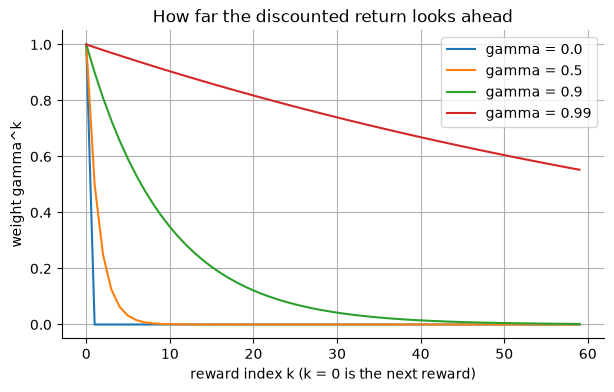

In [7]:
ks = np.arange(N_HORIZON)
horizon = {g: int(np.argmax(1 - g ** (ks + 1) >= COVER)) + 1 for g in GAMMAS_HORIZON}
horizon_closed = {g: int(np.ceil(np.log(1 - COVER) / np.log(g))) for g in GAMMAS_HORIZON}
print("Rewards needed to collect 95% of the endless +1 return:", horizon, "| closed form:", horizon_closed)
fig, ax = plt.subplots()
for g in (0.0, 0.5, 0.9, 0.99):
    ax.plot(ks[:N_PLOT], g ** ks[:N_PLOT], label=f"gamma = {g}")
ax.set(
    xlabel="reward index k (k = 0 is the next reward)",
    ylabel="weight gamma^k",
    title="How far the discounted return looks ahead",
)
ax.legend()
plt.show()

In [8]:
choice_ok = []
for g in GAMMAS_CHOICE:
    grab, wait = returns_recursive(R_GRAB, g)[0], returns_recursive(R_WAIT, g)[0]
    verdict = "tie" if np.isclose(grab, wait) else ("wait" if wait > grab else "grab")
    choice_ok.append(verdict == ("tie" if g == 0.1 else "wait" if g > 0.1 else "grab"))
    print(f"gamma={g:<4}: take 1 now G_0={grab:.2f}, wait for 10 G_0={wait:.2f} -> {verdict}")
print("Checkpoint: grab below gamma = 1/10, tie at 1/10, wait above (where 10*gamma = 1):", all(choice_ok))

gamma=0.0 : take 1 now G_0=1.00, wait for 10 G_0=0.00 -> grab
gamma=0.05: take 1 now G_0=1.00, wait for 10 G_0=0.50 -> grab
gamma=0.1 : take 1 now G_0=1.00, wait for 10 G_0=1.00 -> tie
gamma=0.2 : take 1 now G_0=1.00, wait for 10 G_0=2.00 -> wait
gamma=0.5 : take 1 now G_0=1.00, wait for 10 G_0=5.00 -> wait
gamma=0.9 : take 1 now G_0=1.00, wait for 10 G_0=9.00 -> wait
Checkpoint: grab below gamma = 1/10, tie at 1/10, wait above (where 10*gamma = 1): True


In [9]:
mc_rows = []
for name, pi in (("random policy", PI_RANDOM), ("always push right", PI_RIGHT)):
    policy = tabular_policy(pi)
    rewards = [rollout(env, policy, rng_mc, MAX_STEPS).R for _ in range(N_EP_MC)]
    for g in (1.0, 0.9):
        G0 = np.array([return_direct(R, g) for R in rewards])
        se, exact_v = G0.std(ddof=1) / np.sqrt(N_EP_MC), corridor_expected_return(pi, g)
        mc_rows.append((name, g, G0.mean(), se, exact_v))
        print(f"{name}, gamma={g}: mean G_0 {G0.mean():.3f} +/- {se:.3f} (standard error), exact {exact_v:.3f}")
mc_z = [abs(m - e) / se for _, _, m, se, e in mc_rows]
print("Checkpoint: distance from the exact expected return in standard errors:", np.round(mc_z, 2))

random policy, gamma=1.0: mean G_0 -29.799 +/- 0.380 (standard error), exact -30.000
random policy, gamma=0.9: mean G_0 -8.437 +/- 0.026 (standard error), exact -8.435
always push right, gamma=1.0: mean G_0 -7.845 +/- 0.052 (standard error), exact -7.778
always push right, gamma=0.9: mean G_0 -5.400 +/- 0.020 (standard error), exact -5.381
Checkpoint: distance from the exact expected return in standard errors: [0.53 0.06 1.27 0.92]


### Reading the result

- The recursion reproduces the direct sum at every step: the largest gap over random rewards and four values of $\gamma$ is 1.3e-15, which is rounding error.
- The closed form matches too: 50 rewards of $+1$ give 2.0000 at $\gamma = 0.5$, 9.9485 at $\gamma = 0.9$ and 50 at $\gamma = 1$ (direct sum and formula agree); an endless $+1$ at $\gamma = 0.9$ gives 10.0000, the geometric series $1/(1-\gamma)$.
  At $\gamma = 1$ the partial sums 10, 100, 1000 keep growing, which is why a continuing task needs discounting.
- The plot shows the horizon. Collecting 95% of an endless $+1$ takes the first 5 rewards at $\gamma = 0.5$, 29 at 0.9 and 299 at 0.99, and the closed form agrees. At $\gamma = 0.99$ the weight is still 0.6 at reward index 50; at $\gamma = 0$ only the next reward counts.
- The grab-or-wait choice (1 now against 10 one step later, the latter worth $10\gamma$): at $\gamma = 0$ and 0.05 the agent grabs, at $\gamma = 0.1$ the two returns tie at 1.00, and at 0.2, 0.5 and 0.9 it waits. Chasing the immediate reward lowers the return once $\gamma$ is above 0.1.
- In the corridor the mean return from the start over 4,000 episodes is within 1.3 standard errors of the exact expected return in each of the four printed lines (a linear solve gives the exact values).
  Always pushing right earns about $-7.8$ in total against about $-29.8$ for the random policy (exact $-7.778$ and $-30.000$), so the return orders the policies as it should. The final assertions allow 3 standard errors.

## 3. Pole balancing: two reward schemes

The task: push a cart to keep a hinged pole upright; failure is the pole falling past a given angle, after which the pole is reset.
The same task can be posed in two ways, and both reward keeping the pole up as long as possible. The pole stands for $K$ steps and fails at step $K + 1 = T$:

- **Episodic**: $+1$ on every step without failure (0 on the failing step), so the return $G_0$ is $K$.
- **Continuing with discounting**: $-1$ on failure and $0$ otherwise. The failure reward comes $K$ steps after the first, so an episode that stops at its failure has $G_0 = -\gamma^K$.
  If the task restarts after a failure and goes on, later failures add further discounted $-1$ terms.

The toy replaces the cart-pole physics with a stylised linear model of the pole alone (the cart position and track limit are left out).
The state is the angle $\theta$ (radians) and angular velocity $\omega$; a push adds to $\omega$ and gravity pushes the pole further away from vertical:

$$
\omega' = \omega + \Delta t\,(\kappa\,\theta \pm F) + \sigma \sqrt{\Delta t}\,\xi, \qquad \theta' = \theta + \Delta t\, \omega'
$$

- Time step $\Delta t = 0.02$, tipping rate $\kappa = 10$, push $F = 3$ (right or left), noise scale $\sigma = 1$ and $\xi$ a standard normal draw. Failure is $|\theta| > 0.21$ (about 12 degrees).
- A reset does not give an exactly vertical pole: $\theta$ and $\omega$ are each drawn from a normal distribution with standard deviation 0.02.
- The policy pushes against the lean ($\theta + 0.5\,\omega$) but with probability $\epsilon$ pushes at random instead, so $\epsilon$ sets how good the controller is: 0.1 (good) or 0.6 (weak).
- The continuing scheme uses $\gamma = 0.95$, a choice of this notebook.
- The first experiment stops each episode at its first failure, so there the return $-\gamma^K$ holds by construction of the reward coding: it checks the coding, not an independent truth. The second experiment runs one long stream with resets.

In [10]:
class PoleBalancing:
    """Stylised pole: state (theta, omega); `scheme` is the reward on each step ('episodic': +1 unless failing; 'continuing': -1 only on failure)."""

    def __init__(self, scheme: str):
        self.scheme = scheme

    def reset(self, rng: np.random.Generator) -> np.ndarray:
        return rng.normal(0.0, 0.02, 2)

    def step(self, s: np.ndarray, a: int, rng: np.random.Generator) -> tuple[float, np.ndarray, bool]:
        omega = (
            s[1] + DT * (INSTABILITY * s[0] + (FORCE if a == RIGHT else -FORCE)) + NOISE * np.sqrt(DT) * rng.normal()
        )
        s2 = np.array([s[0] + DT * omega, omega])
        failed = abs(s2[0]) > THETA_MAX
        return (1.0 - failed if self.scheme == "episodic" else -float(failed)), s2, bool(failed)


def balancing_policy(eps: float) -> Callable:
    """Push against the lean; with probability eps push in a random direction."""
    return lambda s, rng: int(rng.integers(2)) if rng.random() < eps else int(s[0] + GAIN * s[1] < 0)

In [11]:
seq_good, seq_weak, seq_stream = np.random.SeedSequence(SEED_POLE).spawn(3)
pole = {}
for name, eps, seq in (("good controller", EPS_GOOD, seq_good), ("weak controller", EPS_WEAK, seq_weak)):
    out = {}
    for scheme in ("episodic", "continuing"):
        r = np.random.default_rng(
            seq
        )  # a fresh generator from the same sequence: both schemes see identical trajectories
        out[scheme] = [rollout(PoleBalancing(scheme), balancing_policy(eps), r, MAX_STEPS) for _ in range(N_EP_POLE)]
    K = np.array([len(t.R) - 1 for t in out["episodic"]])
    G_epi = np.array([return_direct(t.R, 1.0) for t in out["episodic"]])
    G_con = np.array([return_direct(t.R, GAMMA_POLE) for t in out["continuing"]])
    assert all(t.done[-1] for t in out["episodic"])
    pole[name] = dict(K=K, G_con=G_con, err_epi=np.abs(G_epi - K).max(), err_con=np.abs(G_con + GAMMA_POLE**K).max())
    print(
        f"{name} (eps={eps}): mean K {K.mean():.1f}; largest |G_0 - K| (episodic) {pole[name]['err_epi']:.1e}; "
        f"mean continuing G_0 {G_con.mean():.4f}; largest |G_0 + gamma^K| {pole[name]['err_con']:.1e}"
    )
good, weak = pole["good controller"], pole["weak controller"]
order_ok = good["K"].mean() > weak["K"].mean() and good["G_con"].mean() > weak["G_con"].mean()
print("Checkpoint: the better controller has the larger return under both schemes:", order_ok)
print("Continuing return -gamma^K at K =", {k: round(-(GAMMA_POLE**k), 5) for k in K_PROBE})

good controller (eps=0.1): mean K 130.8; largest |G_0 - K| (episodic) 0.0e+00; mean continuing G_0 -0.0546; largest |G_0 + gamma^K| 0.0e+00
weak controller (eps=0.6): mean K 49.4; largest |G_0 - K| (episodic) 0.0e+00; mean continuing G_0 -0.1577; largest |G_0 + gamma^K| 0.0e+00
Checkpoint: the better controller has the larger return under both schemes: True
Continuing return -gamma^K at K = {10: -0.59874, 50: -0.07694, 150: -0.00046, 300: -0.0}


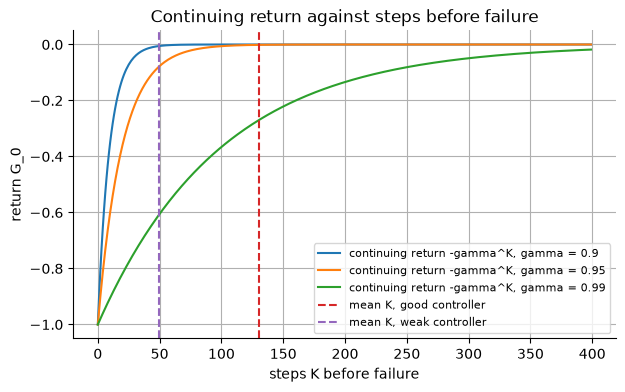

One continuing stream of 4000 steps holds 80 failures; the last episode is cut off at the end of the stream.
Checkpoint: G at each restart equals minus the discounted failures ahead, largest gap 2.2e-16
G at a restart minus (-gamma^K): largest 0.0e+00, smallest -0.1677, mean -0.0254


In [12]:
fig, ax = plt.subplots()
k_grid = np.arange(0, 400)
for g in (0.9, 0.95, 0.99):
    ax.plot(k_grid, -(g**k_grid), label=f"continuing return -gamma^K, gamma = {g}")
for name, color in (("good controller", "C3"), ("weak controller", "C4")):
    ax.axvline(pole[name]["K"].mean(), color=color, ls="--", label=f"mean K, {name}")
ax.set(xlabel="steps K before failure", ylabel="return G_0", title="Continuing return against steps before failure")
ax.legend(fontsize=8)
plt.show()

rng = np.random.default_rng(seq_stream)
stream = rollout(PoleBalancing("continuing"), balancing_policy(EPS_WEAK), rng, N_STREAM, autoreset=True)
G_stream = returns_recursive(stream.R, GAMMA_POLE)
fail = np.flatnonzero(stream.done)
starts = np.r_[0, fail[:-1] + 1]
exact = np.array([-np.sum(GAMMA_POLE ** (fail[i:] - starts[i])) for i in range(len(starts))])
stream_err = np.abs(G_stream[starts] - exact).max()
extra = G_stream[starts] + GAMMA_POLE ** (fail - starts)
print(
    f"One continuing stream of {len(stream.R)} steps holds {len(fail)} failures; the last episode is cut off at the end of the stream."
)
print(f"Checkpoint: G at each restart equals minus the discounted failures ahead, largest gap {stream_err:.1e}")
print(
    f"G at a restart minus (-gamma^K): largest {extra.max():.1e}, smallest {extra.min():.4f}, mean {extra.mean():.4f}"
)

### Reading the result

- Both schemes are coded as stated: the episodic return of every episode equals $K$ and the continuing return equals $-\gamma^K$, with gaps of exactly 0 (a check of the reward coding and of `return_direct`). The good controller lasts 130.8 steps on average and the weak one 49.4.
- The mean continuing return is $-0.0546$ for the good controller and $-0.1577$ for the weak one, so both schemes rank the controllers the same way.
- The plot shows $-\gamma^K$ against $K$ with the two mean $K$ values marked. At $\gamma = 0.95$ it is $-0.59874$ at $K = 10$, $-0.07694$ at 50, $-0.00046$ at 150 and about 0 at 300, so beyond a few hundred steps the continuing return no longer separates controllers, while the episodic return keeps growing in proportion to $K$.
- In one continuing stream of 4,000 steps with 80 failures, the return at a restart minus $-\gamma^K$ lies between $-0.1677$ and 0 with mean $-0.0254$ (for scale, the weak controller's mean return per episode above is $-0.1577$).
  The failure-time formula reproduces the recursion to 2.2e-16; both use the same cut at step 4,000, which drops failures after it and so affects the last few restarts.
- Toy versus book: the physics here is a stylised pole without the cart, so the numbers of steps mean nothing about a real cart-pole; the two reward schemes are as the chapter states.

## 4. The absorbing state unifies episodic and continuing tasks

Episodic returns end at $T$, continuing ones do not, so they look like different objects.
The convention that unifies them treats the end of an episode as entering an **absorbing state**: a state that moves only to itself and pays zero reward.
Then every episode is an infinite sequence with zeros after the end, and one formula covers both tasks:

$$
G_t = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1} = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1} \quad \text{(rewards after } T \text{ are zero)}
$$

- The formula allows $T = \infty$ or $\gamma = 1$, but not both: the sum must stay finite. With $\gamma = 1$ it is finite here only because the episode ends and the later terms are zeros.
- The chapter's example is rewards $+1, +1, +1$ and then zeros.
- The wrapper below turns any episodic environment into an endless one by absorbing at the terminal state; the same loop then runs for a fixed number of steps.
- The corridor is run with the random policy, so episodes have random lengths. For each step $t$ the finite sum (by the recursion, on the episode's own rewards) is compared with the infinite sum written out directly (on the endless run, truncated at 1,500 steps), so the two use different code paths.
  Only the zeros after absorption can make them differ, so this checks the convention and the bookkeeping, not a new fact about returns.

In [13]:
class Absorbing:
    """Wraps an episodic environment: after its terminal step the state is None, which stays None with reward 0."""

    def __init__(self, env):
        self.env = env

    def reset(self, rng: np.random.Generator):
        return self.env.reset(rng)

    def step(self, s, a, rng: np.random.Generator) -> tuple[float, object, bool]:
        if s is None:
            return 0.0, None, False
        r, s2, end = self.env.step(s, a, rng)
        return r, (None if end else s2), False


def absorbing_policy(policy: Callable) -> Callable:
    return lambda s, rng: 0 if s is None else policy(s, rng)

In [14]:
padded = np.r_[BOOK_REWARDS, np.zeros(N_PAD - len(BOOK_REWARDS))]
for g in GAMMAS_ABSORB:
    print(
        f"gamma={g}: G_0 over T=3 rewards {return_direct(BOOK_REWARDS, g):.2f}, over {N_PAD} steps with zeros {return_direct(padded, g):.2f}"
    )

policy = tabular_policy(PI_RANDOM)
gap_abs, lengths = {g: 0.0 for g in GAMMAS_ABSORB}, []
for seq in np.random.SeedSequence(SEED_ABSORB).spawn(N_EP_ABS):
    finite = rollout(env, policy, np.random.default_rng(seq), MAX_STEPS)
    endless = rollout(Absorbing(env), absorbing_policy(policy), np.random.default_rng(seq), N_ABSORB)
    T = len(finite.R)
    assert endless.S[T] is None and np.array_equal(endless.R[:T], finite.R) and not endless.R[T:].any()
    lengths.append(T)
    for g in gap_abs:
        G_infinite = [return_direct(endless.R[t:], g) for t in range(T)]
        gap_abs[g] = max(gap_abs[g], np.abs(returns_recursive(finite.R, g) - G_infinite).max())
print(
    f"Checkpoint: over {N_EP_ABS} episodes (lengths {min(lengths)} to {max(lengths)}) the finite and the endless absorbing-state returns agree at every t; "
    f"largest gap gamma=1: {gap_abs[1.0]:.1e}, gamma=0.9: {gap_abs[0.9]:.1e}"
)

gamma=1.0: G_0 over T=3 rewards 3.00, over 100 steps with zeros 3.00
gamma=0.9: G_0 over T=3 rewards 2.71, over 100 steps with zeros 2.71
Checkpoint: over 200 episodes (lengths 5 to 123) the finite and the endless absorbing-state returns agree at every t; largest gap gamma=1: 0.0e+00, gamma=0.9: 3.6e-15


### Reading the result

- The chapter's example: $G_0$ is 3.00 over the first three rewards and over 100 steps with zeros at $\gamma = 1$, and 2.71 ($1 + 0.9 + 0.81$) in both at $\gamma = 0.9$.
- On 200 corridor episodes of 5 to 123 steps, the finite-horizon return and the endless absorbing-state return agree at every step $t$, at both $\gamma = 1$ and $\gamma = 0.9$ (largest gaps 0.0e+00 and 3.6e-15, rounding error from the different summation orders).
- The wrapper generates the same trajectories, since it consumes no random numbers after absorption; so the absorbing-state view changes how the return is written, not what it is.

## 5. The Markov property

A state signal is **Markov** if it keeps everything in the history that matters for the future:
the next state and reward depend on the history only through the current state and action,

$$
\Pr\{S_{t+1}, R_{t+1} \mid S_0, A_0, R_1, \dots, S_t, A_t\} = p(s', r \mid S_t, A_t).
$$

The toy process is a walk on a ring of 5 positions with momentum: each move is $\pm 1$ and repeats the previous move with probability 0.9.
It has no actions and no rewards, so the Markov condition reduces to that of a Markov chain: the next state depends on the past only through the current state.

- If the state is the **position alone**, it is not Markov: knowing the previous move (equivalently the previous position) predicts the next move, which the position cannot.
- If the state is **position and last move**, it is Markov: the 0.9 rule uses nothing older.
- Exact truth: by symmetry the position alone gives each direction probability 0.5; position plus last move gives 0.9 for repeating it.

A test: for each context (a position, or a position and last move) split the visits by the extra history and compare the next-move frequencies.
A **chi-square test of homogeneity** asks whether the splits could come from the same underlying probability; its **$p$-value** is the chance of a difference at least this large if the extra history did not matter,
so a small $p$-value means it does.
With several contexts tested, the significance level 0.01 is divided by the number of tests (a Bonferroni correction), which keeps the chance of any false alarm at 0.01.
Only one extra step of history is tested here, so a failure to reject is evidence for the Markov property, not proof.

In [15]:
def momentum_walk(n: int, rng: np.random.Generator) -> tuple[np.ndarray, np.ndarray]:
    """Positions and moves of a ring walk that repeats its last move with probability P_KEEP."""
    flips = np.where(rng.random(n) < P_KEEP, 1, -1)
    moves = rng.choice([-1, 1]) * np.cumprod(flips)
    return np.cumsum(moves) % RING, moves


def next_move_table(contexts: np.ndarray, extra: np.ndarray, nxt: np.ndarray) -> np.ndarray:
    """Counts [context, extra history, next move] with next move coded 0 (-1) or 1 (+1)."""
    table = np.zeros((contexts.max() + 1, 2, 2))
    np.add.at(table, (contexts, extra, nxt), 1)
    return table


def homogeneity(table: np.ndarray) -> tuple[float, float]:
    """Smallest p-value over contexts of 'next move does not depend on the extra history', and the largest gap between the conditional probabilities."""
    ps, gaps = [], []
    for ctx in table:
        ps.append(chi2_contingency(ctx)[1])
        gaps.append(abs(np.diff(ctx / ctx.sum(axis=1, keepdims=True), axis=0)[0, 1]))
    return min(ps), max(gaps)

In [16]:
rng = np.random.default_rng(SEED_MARKOV)
pos, mv = momentum_walk(N_MARKOV, rng)
last, nxt, last2 = (mv[1:-1] > 0).astype(int), (mv[2:] > 0).astype(int), (mv[:-2] > 0).astype(int)
p_now = pos[1:-1]

table_pos = next_move_table(p_now, last, nxt)
p_move_pos = table_pos.sum(axis=1)[:, 1] / table_pos.sum(axis=(1, 2))
ctx_pos_last = p_now * 2 + last
table_aug = next_move_table(ctx_pos_last, last2, nxt)
p_move_aug = table_aug.sum(axis=1)[:, 1] / table_aug.sum(axis=(1, 2))
p_pos, gap_pos = homogeneity(table_pos)
p_aug, gap_aug = homogeneity(table_aug)
bonf_pos, bonf_aug = ALPHA_TEST / len(table_pos), ALPHA_TEST / len(table_aug)
print(f"State = position: P(next move +1 | position) = {np.round(p_move_pos, 3)} (exact 0.5)")
print(
    f"  does the previous move matter? smallest p-value {p_pos:.1e} (threshold {bonf_pos:.4f}, {len(table_pos)} tests), "
    f"largest probability gap {gap_pos:.3f} (exact gap {2 * P_KEEP - 1:.1f})"
)
print(
    f"State = position and last move: P(next +1 | position, last move=-1/+1) = {np.round(p_move_aug[::2], 3)} / {np.round(p_move_aug[1::2], 3)} (exact {1 - P_KEEP:.1f}/{P_KEEP})"
)
print(
    f"  does the move before that matter? smallest p-value {p_aug:.3f} (threshold {bonf_aug:.4f}, {len(table_aug)} tests), "
    f"largest probability gap {gap_aug:.3f} (exact 0)"
)

best_pos = np.maximum(p_move_pos, 1 - p_move_pos)[p_now].mean()
best_aug = np.maximum(p_move_aug, 1 - p_move_aug)[ctx_pos_last].mean()
print(
    f"Checkpoint: in-sample next-move accuracy of the best rule estimated from the same data: position alone {best_pos:.3f}, "
    f"position and last move {best_aug:.3f} (exact 0.5 and {P_KEEP})"
)

State = position: P(next move +1 | position) = [0.499 0.5   0.499 0.498 0.499] (exact 0.5)
  does the previous move matter? smallest p-value 0.0e+00 (threshold 0.0020, 5 tests), largest probability gap 0.802 (exact gap 0.8)
State = position and last move: P(next +1 | position, last move=-1/+1) = [0.103 0.1   0.1   0.099 0.099] / [0.896 0.902 0.901 0.897 0.9  ] (exact 0.1/0.9)
  does the move before that matter? smallest p-value 0.236 (threshold 0.0010, 10 tests), largest probability gap 0.009 (exact 0)
Checkpoint: in-sample next-move accuracy of the best rule estimated from the same data: position alone 0.501, position and last move 0.899 (exact 0.5 and 0.9)


### Reading the result

- With the position alone, the probability of moving right is 0.498 to 0.500 at every position, as the symmetry says, but splitting by the previous move changes it sharply: the largest gap between the two conditional probabilities is 0.802 against the exact $2 \times 0.9 - 1 = 0.8$, and the smallest $p$-value underflows to 0, far below the corrected threshold 0.0020 (5 tests). The position is not a Markov state.
- With position and last move, the probability of repeating the last move is 0.896 to 0.902, near the exact 0.9. Splitting by the move before it changes the probabilities by at most 0.009 and the smallest $p$-value is 0.236, above the corrected threshold 0.0010 (10 tests): no evidence of a dependence on that one extra step, consistent with the enlarged state being Markov.
- The estimated best next-move accuracy (a plug-in estimate on the same data, so slightly optimistic) is 0.501 from the position alone and 0.899 from position and last move, against the exact 0.5 and 0.9. A non-Markov state is still usable, since it predicts something, but it leaves information unused; the chapter says to treat such a state as an approximation to a Markov state.
- Hidden information is not the same as a non-Markov state: the chapter notes that a state need not contain what the agent never observed, such as the opponents' cards in poker. The non-Markov problem is information the agent once had and dropped, such as what it saw of the opponents' earlier play. The walk's previous move is of that second kind.

## 6. Checkpoints

In [17]:
checks = [
    ("loop shape: one more state than actions and rewards, terminal flag only at the end", loop_shape_ok),
    (
        "simulator: z-scores of transition frequencies below 4, no impossible transitions",
        z.max() < Z_LIMIT and not impossible_seen,
    ),
    ("recursive and direct returns agree to 1e-12", gap < 1e-12),
    ("closed-form constant returns match direct sums to 1e-9", all(abs(d - c) < 1e-9 for _, d, c in exact_finite)),
    ("endless +1 at gamma = 0.9 is 10 to 1e-6", abs(long_sum - long_closed) < 1e-6),
    ("95% horizon equals the closed form", horizon == horizon_closed),
    ("grab-or-wait switches at gamma = 0.1", all(choice_ok)),
    ("Monte Carlo corridor returns within 3 standard errors of exact", max(mc_z) < MC_SE_LIMIT),
    (
        "pole reward coding: episodic G_0 = K, continuing G_0 = -gamma^K",
        max(p["err_epi"] + p["err_con"] for p in pole.values()) < 1e-12,
    ),
    ("pole: the better controller has the larger return in both schemes", order_ok),
    ("pole stream: restart returns equal the failure-time formula", stream_err < 1e-12),
    ("absorbing-state returns equal finite returns to 1e-9", max(gap_abs.values()) < 1e-9),
    ("walk: position alone rejected (Bonferroni)", p_pos < bonf_pos),
    ("walk: position and last move, no rejection (Bonferroni) and gap below 0.03", p_aug > bonf_aug and gap_aug < 0.03),
    (
        "walk: plug-in accuracy within 0.01 of exact 0.5 and 0.9",
        abs(best_pos - 0.5) < 0.01 and abs(best_aug - P_KEEP) < 0.01,
    ),
]
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)

PASS loop shape: one more state than actions and rewards, terminal flag only at the end
PASS simulator: z-scores of transition frequencies below 4, no impossible transitions
PASS recursive and direct returns agree to 1e-12
PASS closed-form constant returns match direct sums to 1e-9
PASS endless +1 at gamma = 0.9 is 10 to 1e-6
PASS 95% horizon equals the closed form
PASS grab-or-wait switches at gamma = 0.1
PASS Monte Carlo corridor returns within 3 standard errors of exact
PASS pole reward coding: episodic G_0 = K, continuing G_0 = -gamma^K
PASS pole: the better controller has the larger return in both schemes
PASS pole stream: restart returns equal the failure-time formula
PASS absorbing-state returns equal finite returns to 1e-9
PASS walk: position alone rejected (Bonferroni)
PASS walk: position and last move, no rejection (Bonferroni) and gap below 0.03
PASS walk: plug-in accuracy within 0.01 of exact 0.5 and 0.9


In [18]:
summary = pd.DataFrame(
    [
        ("corridor p(s'|s,a): largest z-score", z.max(), Z_LIMIT),
        ("recursive vs direct return: largest gap", gap, 0.0),
        ("+1 for 50 steps, gamma=0.9", return_direct(ones, 0.9), constant_return(1.0, N_CONST, 0.9)),
        ("+1 forever, gamma=0.9 (2000 terms)", long_sum, long_closed),
        ("corridor, random policy, gamma=1: mean G_0", mc_rows[0][2], mc_rows[0][4]),
        ("corridor, always right, gamma=1: mean G_0", mc_rows[2][2], mc_rows[2][4]),
        ("pole good: mean continuing G_0 (coding check)", good["G_con"].mean(), np.mean(-(GAMMA_POLE ** good["K"]))),
        ("absorbing vs finite return: largest gap", max(gap_abs.values()), 0.0),
        ("walk: plug-in accuracy, position only", best_pos, 0.5),
        ("walk: plug-in accuracy, position + last move", best_aug, P_KEEP),
    ],
    columns=["quantity", "result", "reference"],
)
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

                                     quantity    result  reference
          corridor p(s'|s,a): largest z-score     1.869          4
      recursive vs direct return: largest gap 1.332e-15          0
                   +1 for 50 steps, gamma=0.9     9.948      9.948
           +1 forever, gamma=0.9 (2000 terms)        10         10
   corridor, random policy, gamma=1: mean G_0     -29.8        -30
    corridor, always right, gamma=1: mean G_0    -7.845     -7.778
pole good: mean continuing G_0 (coding check)  -0.05462   -0.05462
      absorbing vs finite return: largest gap 3.553e-15          0
        walk: plug-in accuracy, position only    0.5009        0.5
 walk: plug-in accuracy, position + last move    0.8995        0.9
